# 01 - EDA: istraživanje skupa `cars.csv`

Cilj ove sveske je da **razumemo podatke pre nego što išta modelujemo**: šta je u kolonama,
gde su rupe, gde su gluposti, kako izgleda ciljna promenljiva `priceUSD` i šta od toga
određuje odluke u `src/data_cleaning.py` i `src/feature_engineering.py`.

Svaki nalaz ispod ima jasan "šta radimo povodom toga".

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/cars.csv")
print(df.shape)
df.head()

(56244, 12)


,make,model,priceUSD,year,condition,mileage(kilometers),fuel_type,volume(cm3),color,transmission,drive_unit,segment
0,mazda,2,5500,2008,with mileage,162000.0,petrol,1500.0,burgundy,mechanics,front-wheel drive,B
1,mazda,2,5350,2009,with mileage,120000.0,petrol,1300.0,black,mechanics,front-wheel drive,B
2,mazda,2,7000,2009,with mileage,61000.0,petrol,1500.0,silver,auto,front-wheel drive,B
3,mazda,2,3300,2003,with mileage,265000.0,diesel,1400.0,white,mechanics,front-wheel drive,B
4,mazda,2,5200,2008,with mileage,97183.0,diesel,1400.0,gray,mechanics,front-wheel drive,B


## 1. Dimenzije, tipovi i nazivi kolona

56.244 oglasa, 12 kolona. Dve kolone imaju zagrade i jedinice u nazivu
(`mileage(kilometers)`, `volume(cm3)`) - u kodu i formulama to smeta, pa ih u čišćenju
preimenujemo u `mileage_km` i `volume_cm3`.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 56244 entries, 0 to 56243
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   make                 56244 non-null  str    
 1   model                56244 non-null  str    
 2   priceUSD             56244 non-null  int64  
 3   year                 56244 non-null  int64  
 4   condition            56244 non-null  str    
 5   mileage(kilometers)  56244 non-null  float64
 6   fuel_type            56244 non-null  str    
 7   volume(cm3)          56197 non-null  float64
 8   color                56244 non-null  str    
 9   transmission         56244 non-null  str    
 10  drive_unit           54339 non-null  str    
 11  segment              50953 non-null  str    
dtypes: float64(2), int64(2), str(8)
memory usage: 5.1 MB


## 2. Nedostajuće vrednosti

Nedostaju: `segment` (9,4 %), `drive_unit` (3,4 %) i `volume(cm3)` (47 redova).
Segment i pogon su **osobine modela**, pa ih možemo popuniti iz drugih oglasa istog
make+model; ostatak dobija kategoriju `unknown` (nedostajanje je samo po sebi informacija).
Zapremina nedostaje tačno kod električnih vozila - nije greška nego "nema motora sa zapreminom".

In [3]:
missing = df.isna().sum().to_frame("broj").assign(udeo=lambda t: (100 * t["broj"] / len(df)).round(2))
missing[missing["broj"] > 0]

,broj,udeo
volume(cm3),47,0.08
drive_unit,1905,3.39
segment,5291,9.41


In [4]:
df[df["volume(cm3)"].isna()]["fuel_type"].value_counts()

fuel_type
electrocar    47
Name: count, dtype: int64

## 3. Duplikati

87 potpuno identičnih redova - isti oglas uvezen dva puta. Brišemo ih.
Redovi koji se razlikuju samo po ceni (567) su legitimni: dva slična auta, dve cene.

In [5]:
print("identični redovi:", df.duplicated().sum())
print("identični bez cene:", df.duplicated(subset=[c for c in df.columns if c != "priceUSD"]).sum())

identični redovi: 87
identični bez cene: 567


## 4. Ciljna promenljiva: `priceUSD`

Cena ide od 48 $ do 235.235 $, medijana je 5.350 $, a prosek 7.415 $ - **jako zakrivljena
desno**. U log-skali raspodela je skoro zvonasta. Zaključak: modeli uče `log1p(cena)`, a
metrike računamo u dolarima.

In [6]:
df["priceUSD"].describe().round(0)

count     56244.0
mean       7415.0
std        8317.0
min          48.0
25%        2350.0
50%        5350.0
75%        9808.0
max      235235.0
Name: priceUSD, dtype: float64

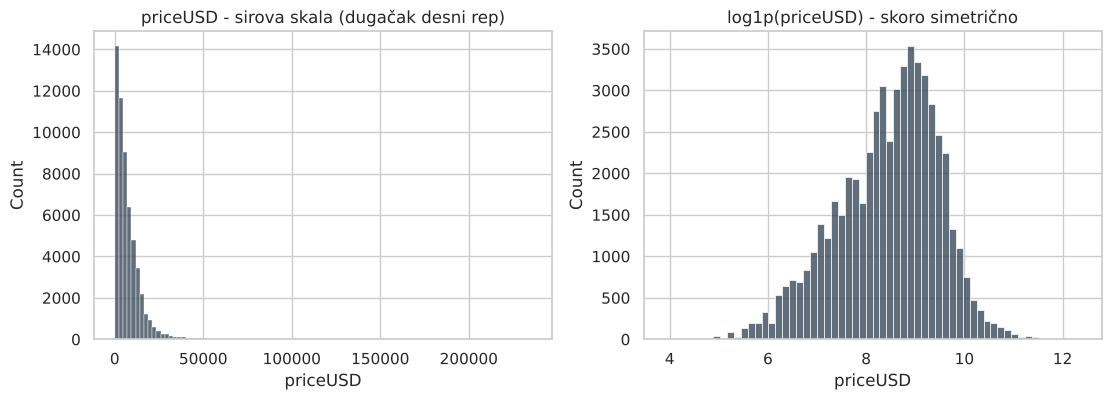

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["priceUSD"], bins=100, ax=axes[0], color="#2c3e50")
axes[0].set_title("priceUSD - sirova skala (dugačak desni rep)")
sns.histplot(np.log1p(df["priceUSD"]), bins=60, ax=axes[1], color="#2c3e50")
axes[1].set_title("log1p(priceUSD) - skoro simetrično")
plt.show()

### Ekstremno male cene

Ispod 300 $ je 370 oglasa. Pogledajmo ko su: skoro svi su `for parts` ili `with damage`,
a ostali su očigledni placeholder-i (100 $, 121 $...). Odluka: `for parts` izbacujemo u
celosti (to je tržište delova, ne automobila), a za ostale postavljamo donju granicu od 300 $.

In [8]:
df.sort_values("priceUSD").head(12)

,make,model,priceUSD,year,condition,mileage(kilometers),fuel_type,volume(cm3),color,transmission,drive_unit,segment
5952,zaz,968,48,1910,with damage,25000.0,petrol,1100.0,green,mechanics,rear drive,B
40252,proton,persona,95,1997,with damage,1111.0,petrol,1600.0,burgundy,mechanics,front-wheel drive,NaN
24873,ford,fiesta,100,1992,for parts,1.0,petrol,1100.0,blue,mechanics,front-wheel drive,B
20971,toyota,corolla,100,1988,for parts,300000.0,petrol,1300.0,red,mechanics,front-wheel drive,C
54171,citroen,xantia,100,1995,for parts,380000.0,petrol,1800.0,silver,mechanics,front-wheel drive,D
23898,ford,escort,100,1986,for parts,200000.0,petrol,1300.0,blue,mechanics,front-wheel drive,C
7314,mercedes-benz,190-w201,100,1991,for parts,2000.0,petrol,2000.0,black,mechanics,NaN,D
41010,nissan,primera,100,1994,for parts,300000.0,petrol,2000.0,burgundy,mechanics,front-wheel drive,D
5456,mazda,626,100,1986,with mileage,100.0,petrol,2000.0,gray,mechanics,front-wheel drive,C
7076,lada-vaz,21099,119,1992,for parts,20000.0,petrol,1500.0,green,mechanics,front-wheel drive,B


In [9]:
df.groupby("condition")["priceUSD"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
condition,,,,,,,,
for parts,454.0,596.0,888.0,100.0,258.0,400.0,600.0,12345.0
with damage,512.0,2721.0,4103.0,48.0,500.0,1000.0,3000.0,27000.0
with mileage,55278.0,7515.0,8344.0,100.0,2500.0,5500.0,9950.0,235235.0


### Ekstremno velike cene

Najskuplji su Bentley, Porsche, Tesla, Maybach - **stvarni automobili sa stvarnim cenama**.
Ne izbacujemo ih: model mora da zna da takvi postoje, a log-cilj sprečava da diktiraju model.

In [10]:
df.sort_values("priceUSD", ascending=False).head(8)

,make,model,priceUSD,year,condition,mileage(kilometers),fuel_type,volume(cm3),color,transmission,drive_unit,segment
20787,bentley,continental-gt,235235,2018,with mileage,29000.0,petrol,6000.0,white,auto,all-wheel drive,NaN
16430,bentley,bentayga,195000,2016,with mileage,72000.0,petrol,6000.0,other,auto,all-wheel drive,NaN
35457,bentley,mulsanne,190141,2014,with mileage,36500.0,petrol,6750.0,purple,auto,rear drive,NaN
16428,bentley,bentayga,183848,2016,with mileage,22000.0,petrol,6000.0,silver,auto,all-wheel drive,NaN
16429,bentley,bentayga,170477,2016,with mileage,74100.0,petrol,6000.0,other,auto,all-wheel drive,NaN
19557,porsche,cayenne,170000,2018,with mileage,1020.0,petrol,4000.0,black,auto,all-wheel drive,J
34508,tesla,model-x,161563,2019,with mileage,50.0,electrocar,NaN,white,auto,part-time four-wheel drive,NaN
26254,mercedes-benz,g-klass,150000,2001,with mileage,160000.0,petrol,5000.0,yellow,auto,part-time four-wheel drive,J


## 5. Numeričke kolone

### Godina proizvodnje
Od 1910 do 2019. **Maksimum 2019 = godina snimka podataka**, pa se starost računa od 2019,
a ne od današnje godine. Ispod 1980 je 258 oldtajmera: njima cena *raste* sa starošću, što
je suprotna zakonitost od ostatka tržišta - izbacujemo ih (model je za moderna polovna vozila).

count    56244.0
mean      2003.0
std          8.0
min       1910.0
25%       1998.0
50%       2004.0
75%       2010.0
max       2019.0
Name: year, dtype: float64
godina < 1980: 258


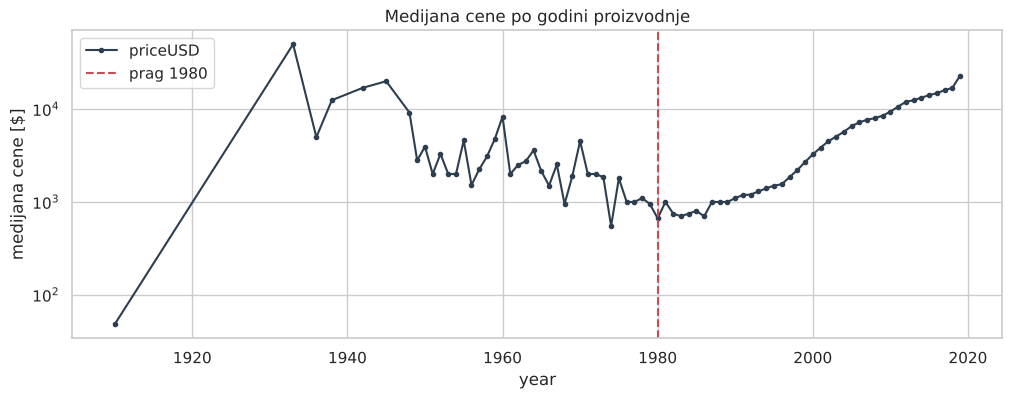

In [11]:
print(df["year"].describe().round(0))
print("godina < 1980:", (df["year"] < 1980).sum())
median_by_year = df.groupby("year")["priceUSD"].median()
fig, ax = plt.subplots(figsize=(12, 4))
median_by_year.plot(ax=ax, marker="o", ms=3, color="#2c3e50")
ax.axvline(1980, color="r", ls="--", label="prag 1980")
ax.set_yscale("log"); ax.set_ylabel("medijana cene [$]"); ax.set_title("Medijana cene po godini proizvodnje")
ax.legend(); plt.show()

### Kilometraža
Medijana 228.500 km, ali maksimum 9.999.999 km. Tri vrste gluposti:
1. **≥ 1.000.000 km** (387 redova): 1111111, 9999999, 3456789 - niko nije prešao toliko;
2. **ponovljene cifre i nizovi** (111111 ×205, 333333 ×160, 123456 ×61...): "ne znam", kucano u obavezno polje;
3. **< 1.000 km na vozilu starom 2+ godine** (~2.300 redova): 0, 1, 100, 172 - kilometraža nije uneta.

Odluka: sve to postaje NaN (red ostaje, ostale kolone su dobre), a `SimpleImputer` ih
popunjava medijanom i dodaje indikator "kilometraža je bila nepoznata".

In [12]:
mil = df["mileage(kilometers)"]
print(mil.quantile([0, .01, .05, .5, .95, .99, .995, 1]).round(0))
print("\n>= 1 milion km:", (mil >= 1e6).sum())
as_text = mil.astype(int).astype(str)
same_digit = as_text[as_text.apply(lambda t: len(t) >= 5 and len(set(t)) == 1)]
print("ponovljene cifre (5+):", len(same_digit))
print(same_digit.value_counts().head(8).to_string())
age = 2019 - df["year"]
print("\n< 1000 km i starost >= 2:", ((mil < 1000) & (age >= 2)).sum())

0.000          0.0
0.010         15.0
0.050       2731.0
0.500     228500.0
0.950     431000.0
0.990     630000.0
0.995    1111111.0
1.000    9999999.0
Name: mileage(kilometers), dtype: float64

>= 1 milion km: 387
ponovljene cifre (5+): 800
mileage(kilometers)
111111     205
333333     160
1111111     85
222222      53
11111       42
999999      35
99999       30
555555      29

< 1000 km i starost >= 2: 2454


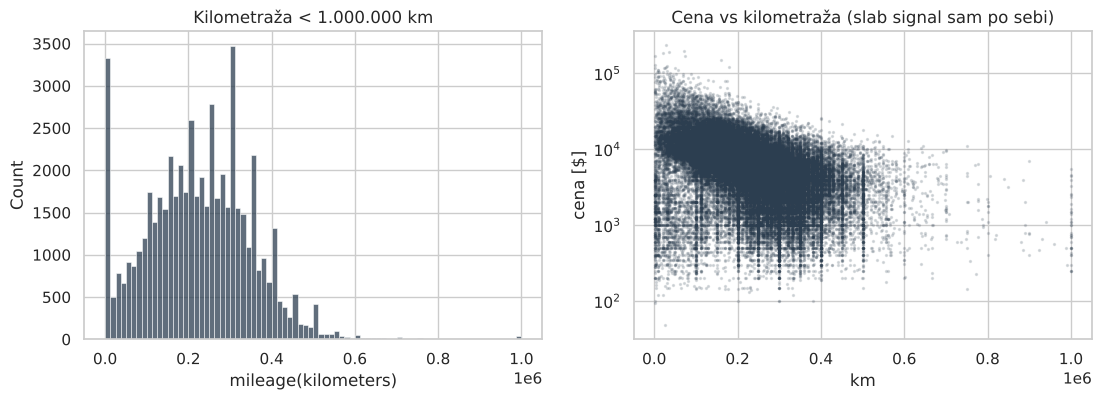

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(mil[mil < 1e6], bins=80, ax=axes[0], color="#2c3e50")
axes[0].set_title("Kilometraža < 1.000.000 km")
valid = (mil >= 1000) & (mil < 1e6)
axes[1].scatter(mil[valid], df.loc[valid, "priceUSD"], s=2, alpha=0.15, color="#2c3e50")
axes[1].set_yscale("log"); axes[1].set_xlabel("km"); axes[1].set_ylabel("cena [$]")
axes[1].set_title("Cena vs kilometraža (slab signal sam po sebi)")
plt.show()

### Zapremina motora
Vrednosti > 7.000 cm³ (94 reda) su tipfeleri sa jednom nulom viška: *mazda 3 = 20000*,
*renault 21 = 16000*, *peugeot 206 = 14000*. Deljenje sa 10 ih vraća na realnu vrednost.

In [14]:
vol = df["volume(cm3)"]
print(vol.describe().round(0))
df[vol > 7000][["make", "model", "year", "volume(cm3)"]].head(10)

count    56197.0
mean      2105.0
std        959.0
min        500.0
25%       1600.0
50%       1996.0
75%       2300.0
max      20000.0
Name: volume(cm3), dtype: float64


,make,model,year,volume(cm3)
81,mazda,3,2006,20000.0
354,mazda,6,2003,20000.0
929,renault,21,1990,16000.0
1537,audi,80,1993,20000.0
1768,audi,100,1992,20000.0
2144,audi,100,1984,18000.0
2479,rover,200,1995,14000.0
2587,peugeot,206,2001,14000.0
3411,peugeot,308,2010,16000.0
3714,mazda,323,1997,13000.0


### Korelacije (log-skala)
Godina je daleko najjači pojedinačni signal (ρ = 0,81 sa log-cenom). Kilometraža je sama po
sebi slab signal (ρ = −0,05!) - zato što stariji auti imaju i više kilometara i nižu cenu, pa
se efekti mešaju. Tek *kilometraža po godini* razdvaja "star auto sa malo km" od "mlad taksi".

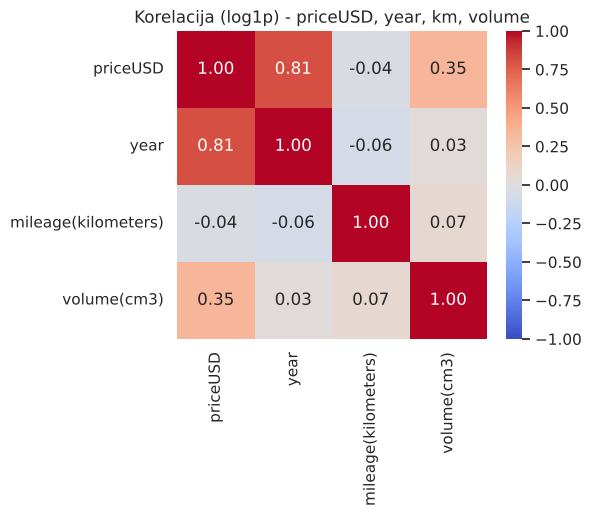

In [15]:
num = df[["priceUSD", "year", "mileage(kilometers)", "volume(cm3)"]].copy()
num = num[(num["mileage(kilometers)"] < 1e6) & (num["volume(cm3)"] <= 7000)]
corr = np.log1p(num).corr()
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Korelacija (log1p) - priceUSD, year, km, volume")
plt.show()

## 6. Kategorijske kolone

- `make`: 96 marki, `model`: 1.034 naziva, `make+model`: 1.071 parova (naziv modela nije
  jedinstven između marki: "3" je i mazda 3 i bmw 3). Pola parova ima ≤ 10 oglasa -
  OneHot bi dao 1.000+ retkih kolona, pa `brand_model` kodujemo **target encoding-om**.
- `condition`: 3 vrednosti; `fuel_type`: 3 (47 električnih); `transmission`: 2;
  `drive_unit`: 4; `segment`: 9 (A-S); `color`: 13. Sve već uredno (mala slova, bez praznina).
- Marka `eksklyuziv` (55 oglasa: *retro*, *voennaya-tehnika*, *kart*, *samodelnyj*, *avtodom*)
  nije marka nego "sve ostalo" - izbacujemo.

In [16]:
for col in ["condition", "fuel_type", "transmission", "drive_unit", "segment", "color"]:
    print(f"--- {col} ({df[col].nunique()} vrednosti) ---")
    print(df[col].value_counts(dropna=False).to_string())
    print()

--- condition (3 vrednosti) ---
condition
with mileage    55278
with damage       512
for parts         454

--- fuel_type (3 vrednosti) ---
fuel_type
petrol        36405
diesel        19792
electrocar       47

--- transmission (2 vrednosti) ---
transmission
mechanics    36056
auto         20188

--- drive_unit (4 vrednosti) ---
drive_unit
front-wheel drive             38016
rear drive                     6836
all-wheel drive                5890
part-time four-wheel drive     3597
NaN                            1905

--- segment (9 vrednosti) ---
segment
D      12605
C      10617
J       8629
M       6313
E       6274
NaN     5291
B       4393
F        896
S        765
A        461

--- color (13 vrednosti) ---
color
black       12385
silver      10075
blue         8083
gray         5807
white        5292
green        3911
other        3397
red          2744
burgundy     2026
brown        1349
purple        625
yellow        317
orange        233



In [17]:
brand_model = df["make"] + "|" + df["model"]
counts = brand_model.value_counts()
print("marki:", df["make"].nunique(), "| modela:", df["model"].nunique(), "| marka+model:", counts.size)
print("parova sa <= 10 oglasa:", (counts <= 10).sum(), "(ukupno", counts[counts <= 10].sum(), "redova)")
df[df["make"] == "eksklyuziv"]["model"].value_counts()

marki: 96 | modela: 1034 | marka+model: 1071
parova sa <= 10 oglasa: 543 (ukupno 2013 redova)


model
avtodom             9
baggi               9
vezdehod            9
retro               8
redkaya-model       6
voennaya-tehnika    5
kart                3
samodelnyj          3
sport               3
Name: count, dtype: int64

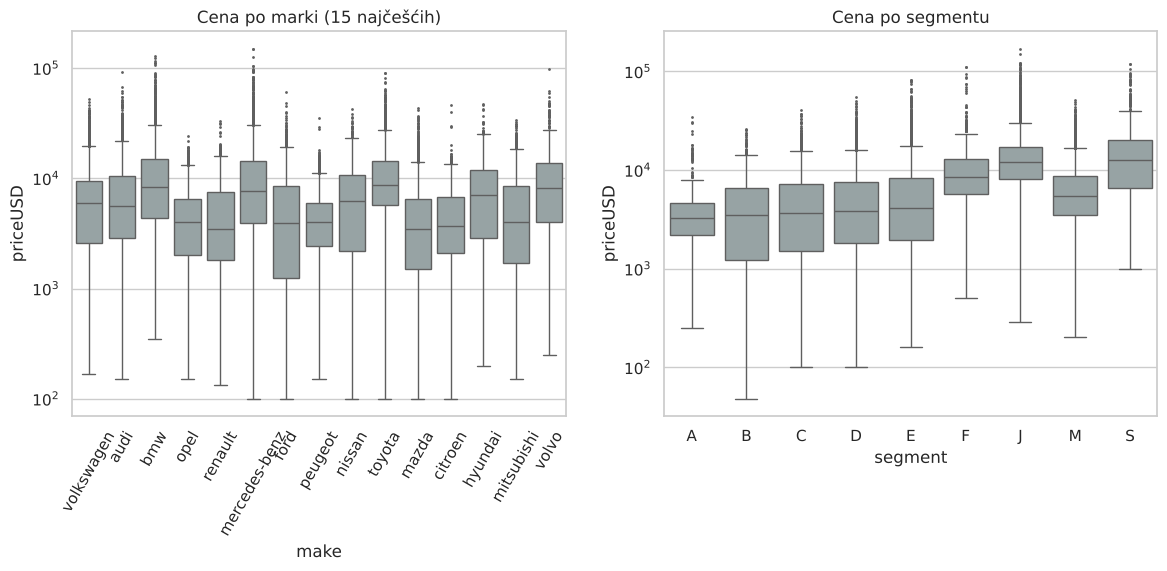

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top = df["make"].value_counts().head(15).index
sns.boxplot(data=df[df["make"].isin(top)], x="make", y="priceUSD", order=top, ax=axes[0], color="#95a5a6", fliersize=1)
axes[0].set_yscale("log"); axes[0].tick_params(axis="x", rotation=60); axes[0].set_title("Cena po marki (15 najčešćih)")
order = ["A", "B", "C", "D", "E", "F", "J", "M", "S"]
sns.boxplot(data=df, x="segment", y="priceUSD", order=order, ax=axes[1], color="#95a5a6", fliersize=1)
axes[1].set_yscale("log"); axes[1].set_title("Cena po segmentu")
plt.show()

## 7. Rezime odluka

| Nalaz | Odluka | Gde |
|---|---|---|
| nazivi kolona sa zagradama | `mileage_km`, `volume_cm3` | `data_cleaning.py` |
| 87 identičnih redova | brišemo | `data_cleaning.py` |
| `for parts` (454) | izbacujemo - tržište delova | `data_cleaning.py` |
| marka `eksklyuziv` (55) | izbacujemo - nije marka | `data_cleaning.py` |
| godina < 1980 (258) | izbacujemo - oldtajmeri | `data_cleaning.py` |
| cena < 300 $ | izbacujemo - placeholder | `data_cleaning.py` |
| km ≥ 1M, ponovljene cifre, < 1000 km na starom autu | NaN + imputer + indikator | `data_cleaning.py` + `data_preprocessing.py` |
| zapremina > 7000 cm³ | /10 (tipfeler) | `data_cleaning.py` |
| električna vozila bez zapremine | 0 | `data_cleaning.py` |
| segment / pogon nedostaju | iz istog make+model, inače `unknown` | `data_cleaning.py` |
| cena jako zakrivljena | model uči `log1p(cena)` | `data_preprocessing.py` |
| godina ≫ kilometraža kao signal | `car_age` (od 2019), `mileage_per_year` | `feature_engineering.py` |
| 1.000+ modela | `brand_model` + target encoding | `feature_engineering.py` + `data_preprocessing.py` |